---
title: "Figures: Aiyagari: Precautionary Saving in GE"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Computes the stationary equilibrium of the economy in [Aiyagari: Precautionary Saving in GE](#sec:Aiyagari), draws its figures, and checks the numbers it quotes. Run all the cells to redraw the figures into `figures/`; change the parameters to see how the equilibrium responds.

The household's problem is solved by the method of endogenous gridpoints, the stationary distribution of wealth is computed on a fine grid rather than by simulating households, and the equilibrium interest rate is found by root-finding on the gap between the capital households supply and the capital firms demand. A cell near the end solves the same household problem with HARK's `MarkovConsumerType` and confirms the answer. The Econ-ARK REMARK [`Aiyagari1994QJE`](https://github.com/econ-ark/Aiyagari1994QJE) reproduces the paper with HARK by simulation.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm

from intertemporal_choice import style

style.use_book_style()

## Parameters

Aiyagari's baseline: a period is a year; $\beta=0.96$, a capital share $\alpha=0.36$ and depreciation $\delta=0.08$. Relative risk aversion $\rho=3$. The log of the idiosyncratic labor productivity component $\ell$ follows an AR(1) with persistence $\varrho=0.6$ and unconditional standard deviation $\sigma=0.2$, approximated by a seven-state Markov chain. No borrowing is allowed.

In [ ]:
beta, alpha, delta = 0.96, 0.36, 0.08   # time preference factor, capital share, depreciation
CRRA = 3.0                              # relative risk aversion (the book's rho)
corr, sigma = 0.6, 0.2                  # persistence and unconditional sd of log labor endowment
n_states = 7

time_pref_rate = 1 / beta - 1           # the time preference rate; complete markets set r to it

## The idiosyncratic labor productivity component

Tauchen's method spreads seven points evenly over three unconditional standard deviations on either side of the mean of $\log\ell$ and assigns each the probability that the AR(1) lands closest to it. The levels are scaled so that aggregate labor, $L=\mathbb{E}[\ell]$ under the chain's stationary distribution, is one.

In [ ]:
def tauchen(n, corr, sd_innovation, width=3.0):
    """Tauchen (1986): an n-state chain for x' = corr x + sd_innovation e, e ~ N(0,1)."""
    sd_x = sd_innovation / np.sqrt(1 - corr**2)
    x = np.linspace(-width * sd_x, width * sd_x, n)
    half_step = (x[1] - x[0]) / 2
    P = np.empty((n, n))
    for i in range(n):
        upper = norm.cdf((x - corr * x[i] + half_step) / sd_innovation)
        lower = norm.cdf((x - corr * x[i] - half_step) / sd_innovation)
        P[i] = upper - lower
        P[i, 0], P[i, -1] = upper[0], 1 - lower[-1]   # the end states take the tails
    return x, P


def stationary_distribution(P):
    """The left eigenvector of P with eigenvalue one, normalized to sum to one."""
    values, vectors = np.linalg.eig(P.T)
    pi = np.real(vectors[:, np.argmin(abs(values - 1))])
    return pi / pi.sum()

## Firms

With aggregate labor equal to one, the firm's first-order conditions give the capital it wants at each interest rate, $K(r)=(\alpha/(r+\delta))^{1/(1-\alpha)}$, and the wage $\mathsf{W}=(1-\alpha)K^{\alpha}$.

In [ ]:
def capital_demand(r):
    return (alpha / (r + delta)) ** (1 / (1 - alpha))


def wage(r):
    return (1 - alpha) * capital_demand(r) ** alpha

## Households

A household with market resources $m$ in income state $i$ chooses consumption $c$ and end-of-period assets $a=m-c\geq 0$; next period it has $m'=\mathsf{R}a+\mathsf{W}\ell_{j}$ with probability $P_{ij}$. The method of endogenous gridpoints starts from a grid of $a$, computes next period's marginal utility at each $a$, inverts the Euler equation $\mathrm{u}^{\prime}(c)=\beta\mathsf{R}\,\mathbb{E}[\mathrm{u}^{\prime}(c')]$ for the $c$ that is optimal with those assets, and recovers the $m=a+c$ at which that choice is made. Below the smallest such $m$ the constraint binds and the household spends everything. Starting from the last period of life, $c(m)=m$, and repeating until the consumption function stops changing gives the infinite-horizon solution.

The distribution of households over assets and income states is then found without simulation: each household's next-period assets fall between two points of a fine grid, and its mass is split between them in proportion to distance, which keeps aggregate assets exact. Repeating the step until the distribution stops changing gives the stationary distribution, and its mean is the capital households supply, $\mathbb{E}a(r)$.

In [ ]:
def interpolate(x, xp, fp):
    """Linear interpolation that extends the last segment, rather than holding it flat, above xp[-1]."""
    y = np.interp(x, xp, fp)
    above = x > xp[-1]
    slope = (fp[-1] - fp[-2]) / (xp[-1] - xp[-2])
    y[above] = fp[-1] + slope * (x[above] - xp[-1])
    return y


class AiyagariEconomy:
    def __init__(self, CRRA=CRRA, corr=corr, sigma=sigma, a_max=200.0):
        self.CRRA = CRRA
        log_ell, self.P = tauchen(n_states, corr, sigma * np.sqrt(1 - corr**2))
        self.pi = stationary_distribution(self.P)
        self.ell = np.exp(log_ell) / (self.pi @ np.exp(log_ell))   # aggregate labor is one
        self.a_grid = a_max * np.linspace(0, 1, 300) ** 3          # dense near the constraint
        self.a_fine = a_max * np.linspace(0, 1, 3000) ** 3

    def solve_household(self, r, tol=1e-9):
        """Consumption at the endogenous gridpoints m_end, for each income state."""
        R, W, a = 1 + r, wage(r), self.a_grid
        m_end = np.tile(a[1:], (n_states, 1))   # the last period: consume everything
        c_end = m_end.copy()
        for _ in range(10000):
            m_next = R * a + W * self.ell[:, None]                     # [next state, a]
            c_next = np.array([interpolate(m_next[j], np.r_[0, m_end[j]], np.r_[0, c_end[j]])
                               for j in range(n_states)])
            c_new = (beta * R * self.P @ c_next ** -self.CRRA) ** (-1 / self.CRRA)
            converged = c_new.shape == c_end.shape and np.max(abs(c_new - c_end)) < tol
            m_end, c_end = a + c_new, c_new
            if converged:
                break
        self.r, self.W, self.m_end, self.c_end = r, W, m_end, c_end

    def c(self, i, m):
        """The consumption function in income state i."""
        return interpolate(np.atleast_1d(m).astype(float), np.r_[0, self.m_end[i]], np.r_[0, self.c_end[i]])

    def stationary_wealth(self, tol=1e-12):
        """Mass of households by income state and end-of-period assets; returns mean assets."""
        R, g = 1 + self.r, self.a_fine
        # Where each grid point's households land next period, for each next income state j
        lower, weight = [], []
        for j in range(n_states):
            m = R * g + self.W * self.ell[j]
            a_next = np.clip(m - self.c(j, m), g[0], g[-1])
            k = np.clip(np.searchsorted(g, a_next) - 1, 0, len(g) - 2)
            lower.append(k)
            weight.append((a_next - g[k]) / (g[k + 1] - g[k]))
        D = np.outer(self.pi, np.full(len(g), 1 / len(g)))
        for _ in range(50000):
            D_new = np.zeros_like(D)
            for j in range(n_states):
                arriving = self.P[:, j] @ D
                np.add.at(D_new[j], lower[j], arriving * (1 - weight[j]))
                np.add.at(D_new[j], lower[j] + 1, arriving * weight[j])
            converged = np.max(abs(D_new - D)) < tol
            D = D_new
            if converged:
                break
        self.D = D
        return D.sum(axis=0) @ g

    def capital_supply(self, r):
        self.solve_household(r)
        return self.stationary_wealth()

    def equilibrium(self, r_low=-0.03):
        """The interest rate at which households supply the capital firms demand."""
        r_star = brentq(lambda r: self.capital_supply(r) - capital_demand(r), r_low, time_pref_rate - 1e-5,
                        xtol=1e-8)
        K = self.capital_supply(r_star)
        return r_star, K

## The baseline equilibrium

With complete markets the interest rate equals the time preference rate. The saving rate in a steady state is replacement investment over output, $\delta K/Y=\delta\alpha/(r+\delta)$.

In [ ]:
def saving_rate(r):
    return delta * alpha / (r + delta)


economy = AiyagariEconomy()
r_star, K_star = economy.equilibrium()
K_cm = capital_demand(time_pref_rate)

print(f"complete markets:   r = {100 * time_pref_rate:.4f}%, saving rate {100 * saving_rate(time_pref_rate):.2f}%, K = {K_cm:.3f}")
print(f"uninsured risk:     r = {100 * r_star:.4f}%, saving rate {100 * saving_rate(r_star):.2f}%, K = {K_star:.3f}")
print(f"capital is higher by {100 * (K_star / K_cm - 1):.1f}%; Aiyagari's Table II: r = 3.8767%, saving rate 24.25%")

complete markets:   r = 4.1667%, saving rate 23.67%, K = 5.447
uninsured risk:     r = 3.8778%, saving rate 24.25%, K = 5.655
capital is higher by 3.8%; Aiyagari's Table II: r = 3.8767%, saving rate 24.25%


These checks stop the build if the computed numbers stop being the ones the chapter quotes.

In [ ]:
assert np.isclose(100 * r_star, 3.8767, atol=0.005)                       # Table II, to the second decimal
assert np.isclose(100 * saving_rate(r_star), 24.25, atol=0.005)
assert np.isclose(100 * time_pref_rate, 4.1667, atol=1e-4) and np.isclose(100 * saving_rate(time_pref_rate), 23.67, atol=0.005)
assert np.isclose(K_star / K_cm, 1.038, atol=0.0005)
assert np.isclose(K_star, capital_demand(r_star), rtol=1e-6)

## Capital supply and demand

The supply curve is computed point by point, letting the wage move with the interest rate as it does in equilibrium. As $r$ approaches the time preference rate from below, the assets households want to hold grow without bound.

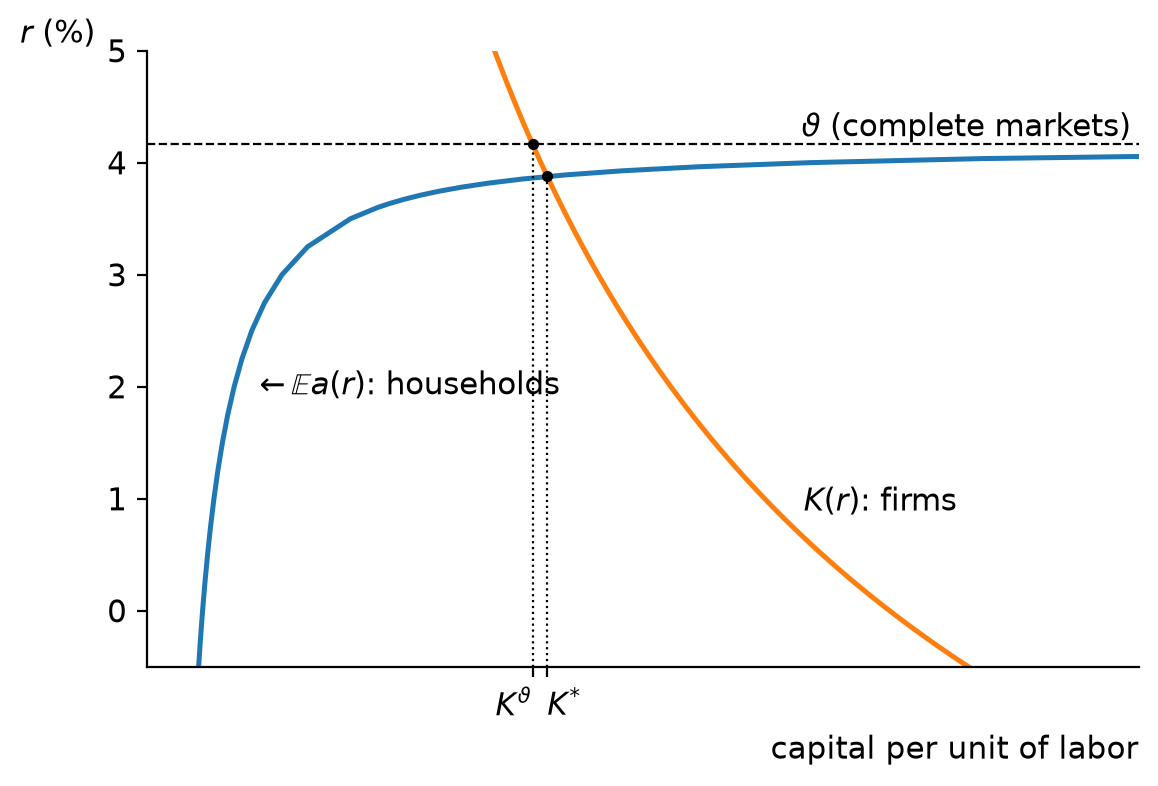

In [ ]:
r_grid = np.r_[np.linspace(-0.005, 0.035, 17), np.linspace(0.036, time_pref_rate - 2e-4, 16)]
supply = np.array([AiyagariEconomy(a_max=600.0).capital_supply(r) for r in r_grid])
assert np.all(np.diff(supply) > 0)    # increasing over this range

fig, ax = plt.subplots()
K_axis = np.linspace(2.0, 14, 200)
ax.plot(supply, 100 * r_grid, color="C0")
ax.plot(K_axis, 100 * (alpha * K_axis ** (alpha - 1) - delta), color="C1")
ax.axhline(100 * time_pref_rate, color="black", linestyle="--", linewidth=0.8)
for K, r in [(K_star, r_star), (K_cm, time_pref_rate)]:
    ax.plot(K, 100 * r, "o", color="black", markersize=3)
    ax.vlines(K, -0.5, 100 * r, color="black", linestyle=":", linewidth=0.8)

ax.text(13.9, 100 * time_pref_rate, r"$\vartheta$ (complete markets)", ha="right", va="bottom")
ax.text(np.interp(2.0, 100 * r_grid, supply), 2.0, r"  $\leftarrow \mathbb{E}a(r)$: households", ha="left", va="center")
ax.text(9.0, 100 * (alpha * 9.0 ** (alpha - 1) - delta), r"  $K(r)$: firms", ha="left", va="bottom")
ax.set_xlim(0, 14)
ax.set_ylim(-0.5, 5)
ax.set_xticks([K_cm, K_star])
ax.set_xticklabels([r"$K^{\vartheta}$", r"$K^{*}$"])
left, right = ax.get_xticklabels()
left.set_horizontalalignment("right")
right.set_horizontalalignment("left")
ax.set_xlabel("capital per unit of labor", loc="right")
ax.set_ylabel(r"$r$ (%)", loc="top", rotation=0)
style.save(fig, "CapitalSupplyDemand")

## The consumption functions

One consumption function for each of the seven income states, at the equilibrium interest rate. Each meets the 45-degree line where the borrowing constraint stops binding.

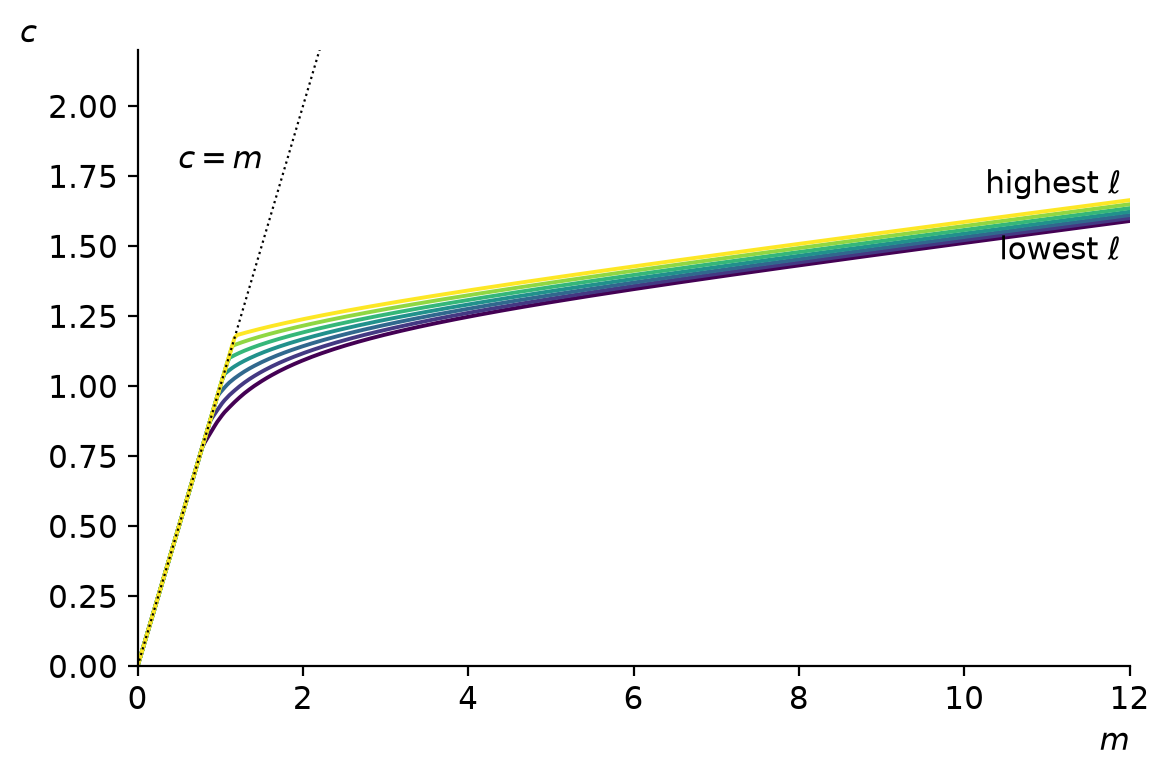

In [ ]:
economy.solve_household(r_star)
m = np.linspace(0, 12, 400)
fig, ax = plt.subplots()
for i in range(n_states):
    ax.plot(m, economy.c(i, m), color=plt.cm.viridis(i / (n_states - 1)), linewidth=1.4)
ax.plot(m, m, color="black", linestyle=":", linewidth=0.8)
ax.text(11.9, economy.c(n_states - 1, 11.9)[0], r"highest $\ell$", ha="right", va="bottom")
ax.text(11.9, economy.c(0, 11.9)[0] - 0.05, r"lowest $\ell$", ha="right", va="top")
ax.text(1.75, 1.75, r"$c=m$  ", ha="right", va="bottom")
ax.set_xlim(0, 12)
ax.set_ylim(0, 2.2)
ax.set_xlabel(r"$m$", loc="right")
ax.set_ylabel(r"$c$", loc="top", rotation=0)
style.save(fig, "ConsFuncByIncomeState")

## The distribution of wealth

Inequality in the stationary distribution, and the average marginal propensity to consume out of a small windfall. U.S. top wealth shares are those Krusell and Smith (1998, Table 1) report: the richest 1, 5, 10, 20 and 30 percent hold 30, 51, 64, 79 and 88 percent of wealth.

In [ ]:
economy.capital_supply(r_star)
mass = economy.D.sum(axis=0)
wealth = economy.a_fine
share_of_people = np.cumsum(mass)
share_of_wealth = np.cumsum(mass * wealth) / (mass @ wealth)


def top_share(q):
    return 1 - np.interp(1 - q, share_of_people, share_of_wealth)


gini = 1 - np.sum(mass * (share_of_wealth + np.r_[0, share_of_wealth[:-1]]))
p10, p90 = np.interp([0.1, 0.9], share_of_people, wealth)
constrained = mass[0]

# Average marginal propensity to consume, over households at the start of a period
R, mpc_sum = 1 + r_star, 0.0
for j in range(n_states):
    m_j = R * wealth + economy.W * economy.ell[j]
    mpc_j = (economy.c(j, m_j + 1e-4) - economy.c(j, m_j)) / 1e-4
    mpc_sum += (economy.P[:, j] @ economy.D) @ mpc_j

print(f"wealth Gini {gini:.2f}; top 1% hold {100 * top_share(0.01):.0f}%, top 10% {100 * top_share(0.10):.0f}%")
print(f"10th and 90th percentiles of wealth: {p10:.1f} and {p90:.1f}, against a mean of {K_star:.1f}")
print(f"share of households at the borrowing constraint: {100 * constrained:.1f}%")
# A perfect foresight consumer with the same preferences and interest rate spends 1 - Thorn_R of wealth,
# where Thorn_R = (R beta)^(1/rho) / R is the return patience factor
mpc_perfect_foresight = 1 - (R * beta) ** (1 / CRRA) / R
print(f"average annual marginal propensity to consume: {mpc_sum:.3f} (perfect foresight, same preferences: {mpc_perfect_foresight:.3f})")

assert np.isclose(gini, 0.39, atol=0.005)
assert np.isclose(100 * top_share(0.01), 4, atol=0.5) and np.isclose(100 * top_share(0.10), 26, atol=0.5)
assert np.isclose(p10, 1.3, atol=0.05) and np.isclose(p90, 11.2, atol=0.05)
assert constrained < 0.005
assert np.isclose(mpc_sum, 0.055, atol=0.0005)
assert np.isclose(mpc_perfect_foresight, 0.038, atol=0.0005)

wealth Gini 0.39; top 1% hold 4%, top 10% 26%
10th and 90th percentiles of wealth: 1.3 and 11.2, against a mean of 5.7
share of households at the borrowing constraint: 0.3%
average annual marginal propensity to consume: 0.055 (perfect foresight, same preferences: 0.038)


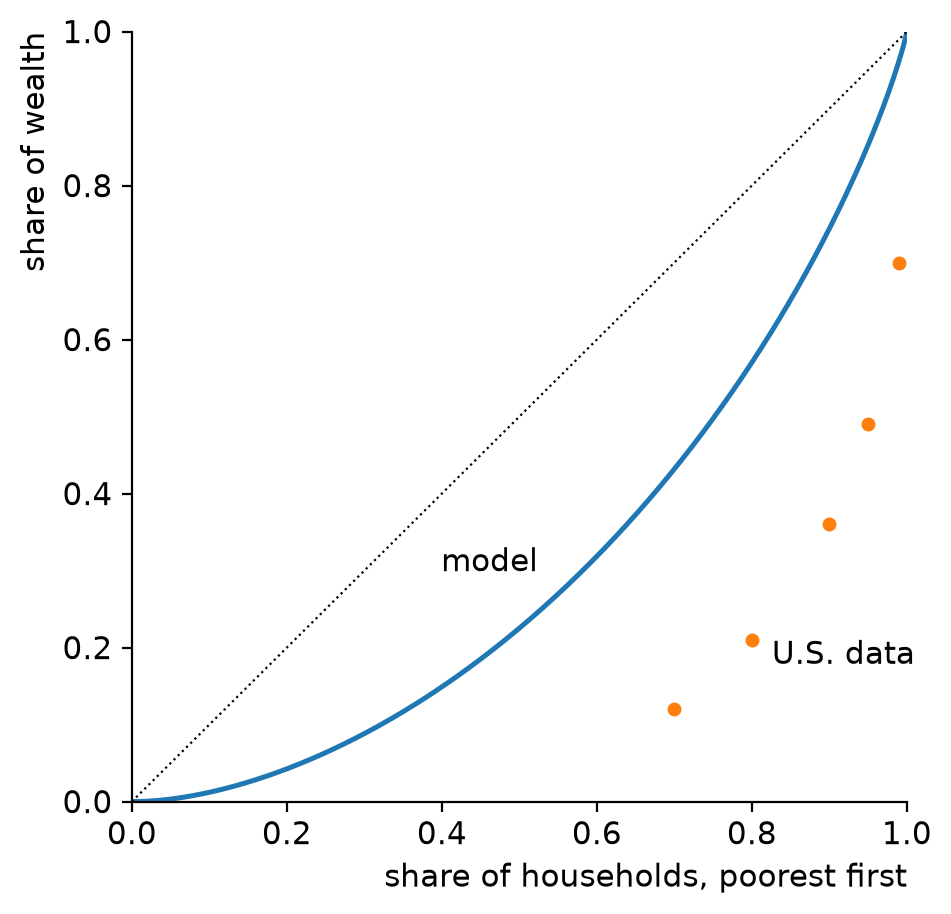

In [ ]:
data_top = np.array([0.01, 0.05, 0.10, 0.20, 0.30])
data_share = np.array([0.30, 0.51, 0.64, 0.79, 0.88])

fig, ax = plt.subplots(figsize=(5.0, 5.0))
ax.plot(np.r_[0, share_of_people], np.r_[0, share_of_wealth], color="C0")
ax.plot(1 - data_top, 1 - data_share, "o", color="C1", markersize=4)
ax.plot([0, 1], [0, 1], color="black", linestyle=":", linewidth=0.8)
x_label = 0.55
ax.text(x_label, np.interp(x_label, share_of_people, share_of_wealth) + 0.02, "model  ", ha="right", va="bottom")
ax.text(0.80, 0.21, "  U.S. data", ha="left", va="top")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("share of households, poorest first", loc="right")
ax.set_ylabel("share of wealth", loc="top")
style.save(fig, "WealthLorenz")

## Aiyagari's Table II

The net interest rate for each of the paper's 24 combinations of income risk, persistence and risk aversion, beside the published value. The saving rate follows from the interest rate, so it is not repeated. This cell takes a few minutes.

In [ ]:
published = {  # (sigma, corr): r in percent for relative risk aversion 1, 3, 5 (Aiyagari 1994, Table II)
    (0.2, 0.0): [4.1666, 4.1456, 4.0858], (0.2, 0.3): [4.1365, 4.0432, 3.9054],
    (0.2, 0.6): [4.0912, 3.8767, 3.5857], (0.2, 0.9): [3.9305, 3.2903, 2.5260],
    (0.4, 0.0): [4.0649, 3.7816, 3.4177], (0.4, 0.3): [3.9554, 3.4188, 2.8032],
    (0.4, 0.6): [3.7567, 2.7835, 1.8070], (0.4, 0.9): [3.3054, 1.2894, -0.3456],
}
gaps = []
print("sigma  persistence   r for relative risk aversion 1, 3, 5 (published in brackets)")
for (s, p), pub in published.items():
    row = []
    for rra, r_pub in zip([1, 3, 5], pub):
        r_eq, _ = AiyagariEconomy(CRRA=rra, corr=p, sigma=s, a_max=400.0 if p == 0.9 else 200.0).equilibrium()
        gaps.append(100 * r_eq - r_pub)
        row.append(f"{100 * r_eq:7.4f} [{r_pub:7.4f}]")
    print(f" {s}       {p}     " + "   ".join(row))
print(f"largest gap {max(abs(g) for g in gaps):.2f} percentage points")
assert max(abs(g) for g in gaps) < 0.3

sigma  persistence   r for relative risk aversion 1, 3, 5 (published in brackets)


 0.2       0.0      4.1450 [ 4.1666]    4.0879 [ 4.1456]    4.0137 [ 4.0858]


 0.2       0.3      4.1271 [ 4.1365]    4.0232 [ 4.0432]    3.8902 [ 3.9054]


 0.2       0.6      4.0870 [ 4.0912]    3.8778 [ 3.8767]    3.6163 [ 3.5857]


 0.2       0.9      3.9531 [ 3.9305]    3.3715 [ 3.2903]    2.6739 [ 2.5260]


 0.4       0.0      4.0594 [ 4.0649]    3.7838 [ 3.7816]    3.4491 [ 3.4177]


 0.4       0.3      3.9754 [ 3.9554]    3.4914 [ 3.4188]    2.9351 [ 2.8032]


 0.4       0.6      3.8031 [ 3.7567]    2.9143 [ 2.7835]    1.9959 [ 1.8070]


 0.4       0.9      3.3959 [ 3.3054]    1.5125 [ 1.2894]   -0.0883 [-0.3456]
largest gap 0.26 percentage points


## An AR(1) fitted to permanent and transitory shocks

Simulated household income histories from the process in which Friedman's and Muth's distinction is exact: log income is a random walk $p$ plus white noise $\theta$, with the standard deviations Carroll (1992, Table 2) estimates for family noncapital income in the PSID, $0.126$ for the permanent shock and $0.163$ for the transitory one. An AR(1) is fitted to each household's history, allowing each household its own mean. Persistence is then estimated again from the ratio of the second to the first autocovariance, which the transitory shocks do not affect; that is the estimate an ARMA(1,1), an AR(1) with an MA(1) error, implies.

In [ ]:
rng = np.random.default_rng(0)
households, sd_perm, sd_tran = 20000, 0.126, 0.163
ar1, arma = {}, {}
for years in (10, 20, 40):
    p = np.cumsum(rng.normal(0, sd_perm, (households, years)), axis=1)
    y = p + rng.normal(0, sd_tran, (households, years))
    lag, now = y[:, :-1], y[:, 1:]
    lag, now = lag - lag.mean(1, keepdims=True), now - now.mean(1, keepdims=True)
    ar1[years] = np.mean((lag * now).sum(1) / (lag**2).sum(1))
    y2, y1, y0 = (z - z.mean(1, keepdims=True) for z in (y[:, 2:], y[:, 1:-1], y[:, :-2]))
    arma[years] = (y2 * y0).sum() / (y1 * y0).sum()
    print(f"{years} years: AR(1) coefficient {ar1[years]:.2f}; persistence allowing for the transitory shock {arma[years]:.2f}")

assert np.isclose(ar1[20], 0.44, atol=0.01) and np.isclose(arma[20], 0.83, atol=0.01)
assert ar1[10] < ar1[20] < ar1[40] < 0.7 and arma[40] > 0.9

10 years: AR(1) coefficient 0.19; persistence allowing for the transitory shock 0.55
20 years: AR(1) coefficient 0.44; persistence allowing for the transitory shock 0.83
40 years: AR(1) coefficient 0.63; persistence allowing for the transitory shock 0.92


## The same household problem in HARK

HARK's `MarkovConsumerType` solves the household's problem for a Markov chain of income states. Given the chain, the wage and the equilibrium interest rate, its consumption functions agree with the numpy solver's.

In [ ]:
from HARK.ConsumptionSaving.ConsMarkovModel import MarkovConsumerType
from HARK.distributions import DiscreteDistributionLabeled

economy.solve_household(r_star)
hark = MarkovConsumerType(CRRA=CRRA, DiscFac=beta, cycles=0, BoroCnstArt=0.0,
                          aXtraMax=400, aXtraCount=300, aXtraNestFac=3)
# Permanent income is one throughout; income in state i is W * ell_i, entered as a "transitory" shock
hark.MrkvArray = [economy.P]
hark.IncShkDstn = [[DiscreteDistributionLabeled(pmv=np.ones(1), atoms=np.array([[1.0], [economy.W * ell]]),
                                                var_names=["PermShk", "TranShk"]) for ell in economy.ell]]
hark.Rfree = [np.full(n_states, 1 + r_star)]
hark.LivPrb = [np.ones(n_states)]
hark.PermGroFac = [np.ones(n_states)]
hark.solve()

m = np.linspace(0.5, 25, 60)
gap = max(np.max(abs(hark.solution[0].cFunc[i](m) - economy.c(i, m))) for i in range(n_states))
print(f"largest difference between the two consumption functions: {gap:.1e}")
assert gap < 1e-3

largest difference between the two consumption functions: 1.1e-04
